In [11]:
#!pip install h5py
#!pip install rasterio
#!pip install matplotlib

In [12]:
import h5py
import os
import numpy as np
import rasterio
from rasterio.transform import from_origin
from rasterio.plot import show
import matplotlib.pyplot as plt
from affine import Affine
from rasterio.crs import CRS
from pathlib import Path

In [2]:
new_root = 'D:/LCZ42/'
root_registration = 'D:/LCZ42/tif_saved/'
img_fname = 'validation.h5'
aux_fname = 'validation_geo.h5'

# sample indices to visualize
start_idx = 10020
end_idx = 10024

sen1_data shape: (24119, 32, 32, 8)
Taille de sen1_data revu :  (4, 32, 32, 8)
Taille de sen2_data revu :  (4, 32, 32, 10)
Donnée label en one-hot coding : 
 [[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]
Clés de fid1 : 
 ['coord', 'epsg', 'tfw']
Valeurs du vecteur soi disant tfw : 
 [5.50335858e+05 1.00000000e+01 0.00000000e+00 4.18321443e+06
 0.00000000e+00 1.00000000e+01]

 On remarque simplement dès la première valeur que si l'on compare cela à un TFW (worldfile sur wikipedia), les valeurs ne correspondent pas
Taille de la colonne epsg du h5 : (24119, 1)
All epsg codes : 
 [[32610]
 [32737]
 [32639]
 [32719]]
Leur taille :  (4, 1)
One city : 
  [5.50495858e+05 4.18305443e+06 1.83500000e+03 2.55000000e+03
 1.80000000e+03 2.55000000e+03]


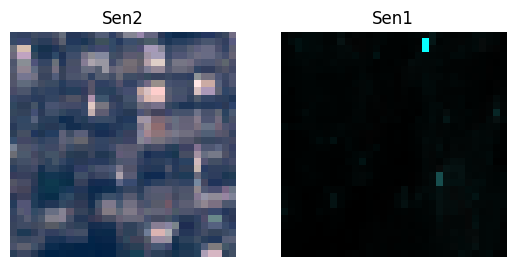

In [6]:
h5_file = os.path.join(new_root,img_fname)

with h5py.File(h5_file, 'r') as fid1:
    sen1_shape = fid1['sen1'].shape
    print("sen1_data shape:", sen1_shape)

with h5py.File(h5_file, 'r') as fid1:
    sen1_data = np.array(fid1['sen1'][start_idx:end_idx])  # (N, patchSize, patchSize, 8)
    sen2_data = np.array(fid1['sen2'][start_idx:end_idx])  # (N, patchSize, patchSize, 10)
    print("Taille de sen1_data revu : ", sen1_data.shape)
    print("Taille de sen2_data revu : ", sen2_data.shape)
    label_data = np.array(fid1['label'][start_idx:end_idx])
    print("Donnée label en one-hot coding : \n", label_data)

h5_file_aux = os.path.join(new_root,aux_fname)

with h5py.File(h5_file_aux, 'r') as fid1:
    print("Clés de fid1 : \n", list(fid1.keys()))
    print("Valeurs du vecteur soi disant tfw : \n" , fid1["tfw"][start_idx])
    print("\n On remarque simplement dès la première valeur que si l'on compare cela à un TFW (worldfile sur wikipedia), les valeurs ne correspondent pas")
    geotransform_new = np.array(fid1['tfw'][start_idx:end_idx]) # Le TFW n'est pas vraiment un TFW, c'est un Geotransform, on va devoir ainsi corriger tout cela
    epsg_new = np.array(fid1['epsg'][start_idx:end_idx])
    print("Taille de la colonne epsg du h5 :", fid1['epsg'].shape)
    coord_new = np.array(fid1['coord'][start_idx:end_idx]) # Permet de voir plus précisément les villes concernées

# Définir l'EPSG à partir du readme et des infos bonus 
# Définir le TFW notamment également
print("All epsg codes : \n", epsg_new)
print("Leur taille : ", epsg_new.shape)
print("One city : \n ", coord_new[0])
plt.subplot(1,2,1)
rgb = sen2_data[0, :, :, 0:3] # BGR
rgb = rgb[:, :, ::-1]  # BGR to RGB
rgb_norm = (rgb - np.min(rgb)) / (np.max(rgb) - np.min(rgb))
plt.imshow(rgb_norm)
plt.axis('off')
plt.title('Sen2')

plt.subplot(1,2,2)
s1 = np.stack([sen1_data[0, :, :, 4], sen1_data[0, :, :, 5], sen1_data[0, :, :, 5]], axis=2)  # false color : visualisation de la végétation apparemment
s1_norm = (s1 - np.min(s1)) / (np.max(s1) - np.min(s1))
plt.imshow(s1_norm)
plt.title('Sen1')
plt.axis('off')

plt.show()

Sen1 montre bien que la grande majorité des pixels porte les mêmes valeurs hormis le bleu très brillant et celui qui brille un peu moins

Test de la cohérence des données d'entrées et leur bon positionnement sur la carte pour la génération de GeoTiffs notamment : 

In [14]:
LCZ_CLASSES = [
    "1. Compact high-rise", "2. Compact mid-rise", "3. Compact low-rise",
    "4. Open high-rise", "5. Open mid-rise", "6. Open low-rise",
    "7. Lightweight low-rise", "8. Large low-rise", "9. Sparsely built",
    "10. Heavy industry", "A. Dense trees", "B. Scattered trees",
    "C. Bush, scrub", "D. Low plants", "E. Bare rock/paved",
    "F. Bare soil/sand", "G. Water",
]

SEN2_BAND_NAMES = ["B2", "B3", "B4", "B5", "B6",
                   "B7", "B8", "B8A", "B11", "B12"]



In [34]:
# Fichiers contenant les informations géographiques correspondantes
TESTING_H5 = Path("D:/LCZ42/testing.h5")
TESTING_GEO_H5 = Path("D:/LCZ42/testing_geo.h5")

LCZ_CODES = [LCZ_CLASSES[i].split(".")[0].strip() for i in range(len(LCZ_CLASSES))]
WATER_CODE = "A"


def _split_has_geo(geo_path: Path) -> bool:
    with h5py.File(geo_path, "r") as f:
        return "tfw" in f and "epsg" in f


def find_most_heterogeneous_water_examples(
    n_best: int = 3,
    band_idx_for_variance: int = 0,
):

    best_examples = []
    water_idx = LCZ_CODES.index(WATER_CODE)


    with h5py.File(TESTING_H5, "r") as f:
        labels = f["label"][:]
        class_idx = np.argmax(labels, axis=1)

        water_rows = np.where(class_idx == water_idx)[0]

        print(f"Nombre de patches LCZ G : {len(water_rows)}")

        sen2 = f["sen2"]

        for row in water_rows:
            patch = sen2[row]

            std = float(np.std(patch[:, :, band_idx_for_variance]))

            example = {
                "row": int(row),
                "std": std,
                "band_idx": band_idx_for_variance,
            }

            best_examples.append(example)

            best_examples.sort(
                key=lambda x: x["std"],
                reverse=True
            )

            if len(best_examples) > n_best:
                best_examples.pop()

    print("\n=== TOP PATCHES LCZ G ===")

    for rank, example in enumerate(best_examples, start=1):
        print(
            f"{rank}. "
            f"row={example['row']} | "
            f"std={example['std']:.4f} | "
            f"band={example['band_idx']}"
        )

    return best_examples

def write_geotiff_for_testing(
    idx_testing: int,
    out_dir: Path,
    tag: str = "",
    display: bool = True,
):
    # 1. Informations géographiques

    with h5py.File(TESTING_GEO_H5, "r") as f:

        if "tfw" not in f or "epsg" not in f:
            print(
                f"{TESTING_GEO_H5} ne contient pas "
                f"'tfw' et/ou 'epsg'."
            )
            return None

        geo6 = f["tfw"][idx_testing]
        epsg_code = int(
            np.asarray(f["epsg"][idx_testing]).reshape(-1)[0]
        )

    # 2. CRS
    try:
        crs = CRS.from_epsg(epsg_code)

    except Exception as exc:
        print(
            f"EPSG {epsg_code} invalide "
            f"({exc}) -- GeoTIFF ignoré."
        )
        return None

    # 3. Transformation affine
    transform = Affine.from_gdal(*[float(v) for v in geo6])

    # 4. Lecture Sentinel-2
    with h5py.File(TESTING_H5, "r") as f:
        sen2_hwc = f["sen2"][idx_testing]

    # (H, W, 10) -> (10, H, W)
    sen2_chw = np.transpose(sen2_hwc,(2, 0, 1)).astype(np.float32)

    # 5. Flip Nord-Sud
    sen2_chw = np.flip(sen2_chw,axis=1).copy()

    # 6. Ordre RGB + autres bandes
    band_order = [2, 1, 0,3, 4, 5, 6, 7, 8, 9]

    sen2_chw = sen2_chw[band_order]

    band_names = [SEN2_BAND_NAMES[i] for i in band_order]
    
    # 7. Écriture GeoTIFF
    suffix = f"_{tag}" if tag else ""

    fname = (
        f"testing_row{idx_testing}"
        f"{suffix}.tif"
    )

    out_dir.mkdir(parents=True, exist_ok=True)

    out_path = out_dir / fname

    H, W = sen2_chw.shape[1:]

    with rasterio.open(
        out_path,
        "w",
        driver="GTiff",
        height=H,
        width=W,
        count=sen2_chw.shape[0],
        dtype=sen2_chw.dtype,
        crs=crs,
        transform=transform,
        compress="DEFLATE",
    ) as dst:

        dst.write(sen2_chw)
        dst.descriptions = band_names

    # 8. Affichage RGB dans le notebook
    if display:

        rgb = np.transpose(sen2_chw[:3],(1, 2, 0))

        # Normalisation robuste pour l'affichage
        p2, p98 = np.percentile(rgb, (2, 98))

        if p98 > p2:
            rgb_display = np.clip((rgb - p2) / (p98 - p2), 0, 1)
        else:
            rgb_display = np.zeros_like(rgb)

        plt.figure(figsize=(8, 8))

        plt.imshow(rgb_display)

        plt.title(
            f"LCZ A — testing row {idx_testing}\n"
            f"EPSG:{epsg_code}"
        )

        plt.axis("off")
        plt.show()

    print(f"GeoTIFF créé : {out_path}")

    return {
        "path": str(out_path),
        "row": idx_testing,
        "epsg": epsg_code,
        "transform": transform,
    }

water_result = find_most_heterogeneous_water_examples(n_best=10, band_idx_for_variance=1)

water_result

Nombre de patches LCZ G : 2368

=== TOP PATCHES LCZ G ===
1. row=10587 | std=0.0249 | band=1
2. row=504 | std=0.0234 | band=1
3. row=8657 | std=0.0229 | band=1
4. row=23842 | std=0.0228 | band=1
5. row=3419 | std=0.0227 | band=1
6. row=12271 | std=0.0225 | band=1
7. row=8901 | std=0.0221 | band=1
8. row=4531 | std=0.0219 | band=1
9. row=9672 | std=0.0218 | band=1
10. row=2541 | std=0.0215 | band=1


[{'row': 10587, 'std': 0.024926515537165832, 'band_idx': 1},
 {'row': 504, 'std': 0.023373327067479157, 'band_idx': 1},
 {'row': 8657, 'std': 0.022870763807097832, 'band_idx': 1},
 {'row': 23842, 'std': 0.022806056735473583, 'band_idx': 1},
 {'row': 3419, 'std': 0.022663636405171602, 'band_idx': 1},
 {'row': 12271, 'std': 0.022498716566992556, 'band_idx': 1},
 {'row': 8901, 'std': 0.022142721238062022, 'band_idx': 1},
 {'row': 4531, 'std': 0.02186430368873145, 'band_idx': 1},
 {'row': 9672, 'std': 0.021770363097617006, 'band_idx': 1},
 {'row': 2541, 'std': 0.021452197835714896, 'band_idx': 1}]

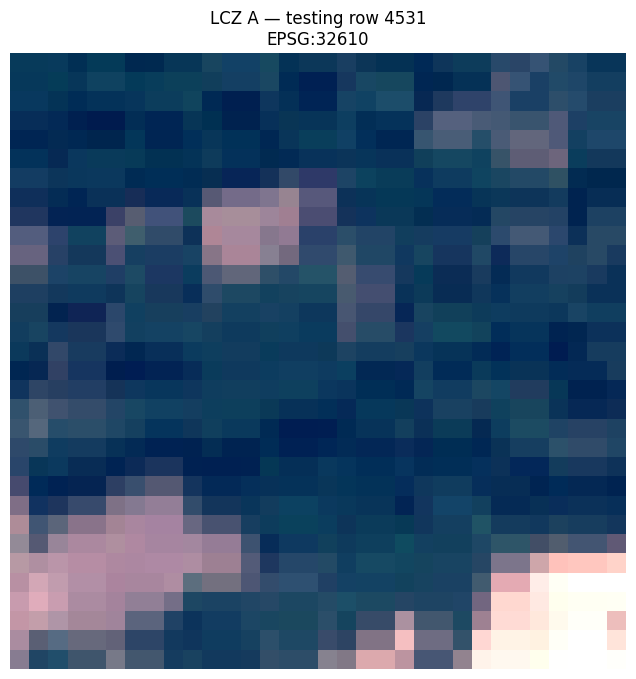

GeoTIFF créé : D:\LCZ42\forest_examples\testing_row4531_LCZA.tif


{'path': 'D:\\LCZ42\\forest_examples\\testing_row4531_LCZA.tif',
 'row': 4531,
 'epsg': 32610,
 'transform': Affine(10.0, 0.0, 569135.8580349555,
        0.0, 10.0, 4192214.4323133323)}

In [37]:
info = write_geotiff_for_testing(
    idx_testing=4531,
    out_dir=Path("D:/LCZ42/forest_examples"),
    tag="LCZA",
)

info

### A comprendre pourquoi les canaux de 0 à 2 appartiennent à Sentinel 2 et le canal 4 appartient à Sentinel 1 et quelles sont les différences

In [15]:
print("Taille de nos datas respectives : ", sen2_data[0, :, :, 4].shape)
print("Taille tenseur final : ", s1.shape)
print("Taille tenseur final normalisé : ", s1_norm.shape)

Taille de nos datas respectives :  (32, 32)
Taille tenseur final :  (32, 32, 3)
Taille tenseur final normalisé :  (32, 32, 3)


Saving sample 10020 ...
Saving sample 10021 ...
Saving sample 10022 ...
Saving sample 10023 ...


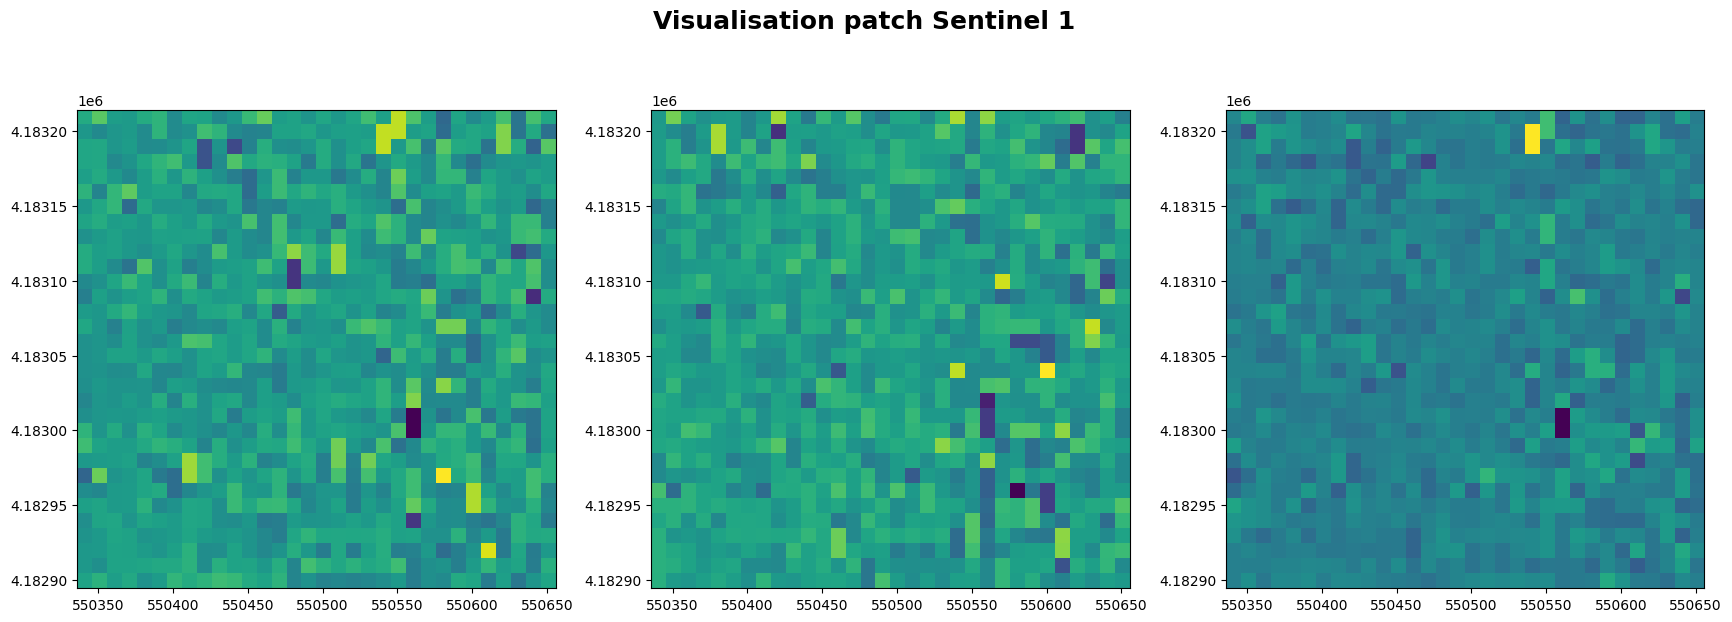

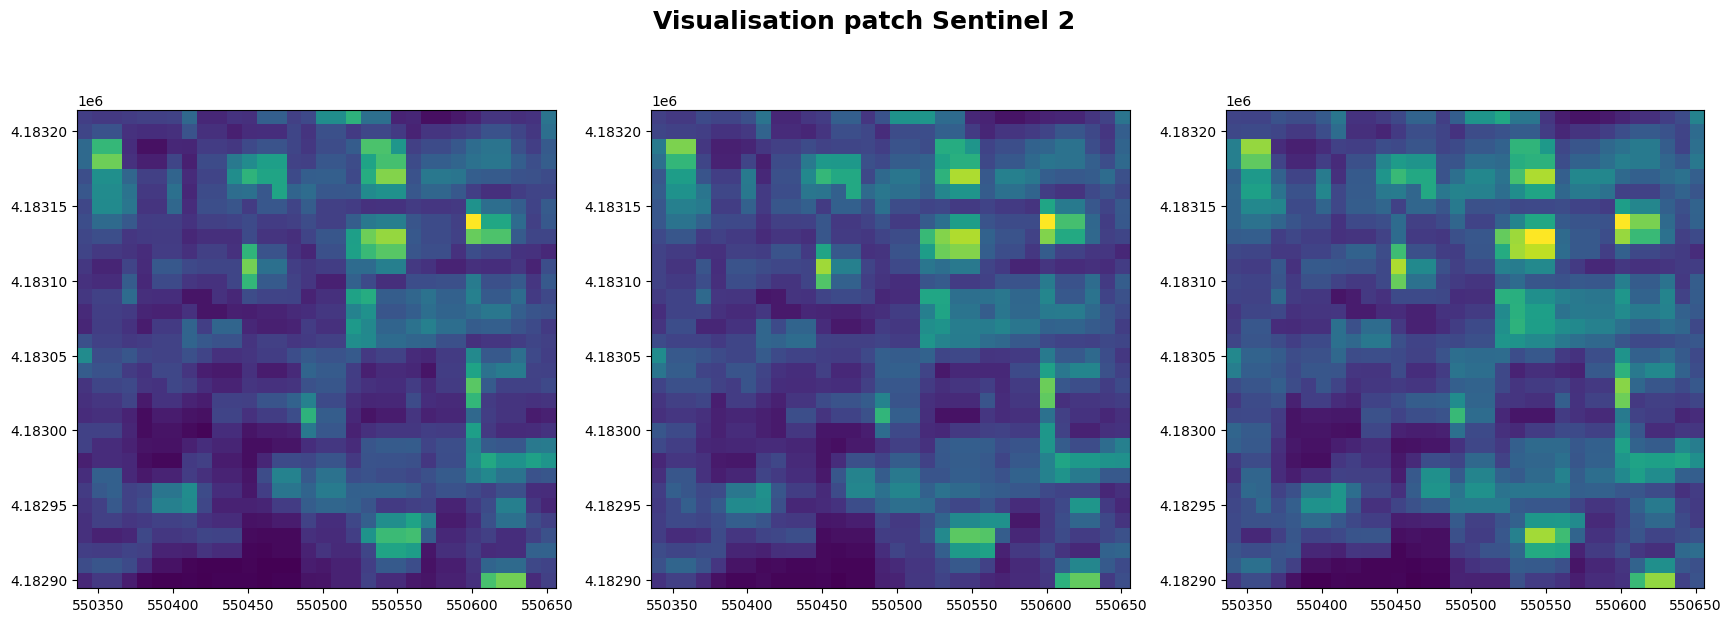

In [ ]:
for sample_idx in range(start_idx, end_idx):
    print(f"Saving sample {sample_idx} ...")

    sample_sen1 = np.transpose(sen1_data[sample_idx - start_idx], (2, 0, 1)) 
    # Pour s'adapter au standard SIG (Système d'Information Géographique) avec toujours la première dimension du tableau numpy doit être le canal
    # Vision un peu par couche que l'on superpose contrairement au cas des pixels par exemple...
    sample_sen2 = np.transpose(sen2_data[sample_idx - start_idx], (2, 0, 1))

    origin_x = geotransform_new[sample_idx - start_idx, 0]
    pixel_width = abs(geotransform_new[sample_idx - start_idx, 1])
    origin_y = geotransform_new[sample_idx - start_idx, 3]
    pixel_height = abs(geotransform_new[sample_idx - start_idx, 5])
    transform = from_origin(origin_x, origin_y, pixel_width, pixel_height)
    epsg_code = int(epsg_new[sample_idx - start_idx, 0])


    #.gpkg 
    # write sen1
    sen1_outfile = os.path.join(root_registration, f'sen1_patch_{sample_idx}.tif')
    with rasterio.open(
        sen1_outfile, 'w',
        driver='GTiff',
        height=sample_sen1.shape[1],
        width=sample_sen1.shape[2],
        count=sample_sen1.shape[0],
        dtype=sample_sen1.dtype,
        crs=f'EPSG:{epsg_code}',
        transform=transform
    ) as dst:
        dst.write(sample_sen1)

    # write sen2
    sen2_outfile = os.path.join(root_registration, f'sen2_patch_{sample_idx}.tif')
    with rasterio.open(
        sen2_outfile, 'w',
        driver='GTiff',
        height=sample_sen2.shape[1],
        width=sample_sen2.shape[2],
        count=sample_sen2.shape[0],
        dtype=sample_sen2.dtype,
        crs=f'EPSG:{epsg_code}',
        transform=transform
    ) as dst:
        dst.write(sample_sen2)
    
    if sample_idx == start_idx:
        with rasterio.open(sen1_outfile) as src:
            fig, (axr, axg, axb) = plt.subplots(1,3, figsize=(21, 7))
            fig.suptitle("Visualisation patch Sentinel 1", fontsize=18, fontweight="bold", y = 0.98)
            show((src, 1), ax=axr)
            show((src, 2), ax=axg)
            show((src, 3), ax=axb)
        
        with rasterio.open(sen2_outfile) as src:
            fig, (axr, axg, axb) = plt.subplots(1,3, figsize=(21, 7))
            fig.suptitle("Visualisation patch Sentinel 2", fontsize=18, fontweight="bold", y=0.98)
            show((src, 1), ax=axr)
            show((src, 2), ax=axg)
            show((src, 3), ax=axb)




    # # Check if the written files have projection information
    # print(f'Checking projection of {sen1_outfile}:')
    # os.system(f'gdalinfo {sen1_outfile} | grep "Coordinate System is"')
    # print(f'Checking projection of {sen2_outfile}:')
    # os.system(f'gdalinfo {sen2_outfile} | grep "Coordinate System is"')

In [17]:
print("Taille notre sample de sen1 : ", sample_sen1.shape)
print("Taille de celui de sen2 : ", sample_sen2.shape)

Taille notre sample de sen1 :  (8, 32, 32)
Taille de celui de sen2 :  (10, 32, 32)
